# ♻️ EcoClasifica — Entrenamiento y evaluación del modelo

**Clasificación de residuos para reciclaje:** Cartón · Papel · Plástico · Vidrio · Metal · Basura (no reciclable)

| Sección | Qué hace |
|---|---|
| 0 | Instala versiones fijas de las librerías y configura el experimento |
| 1 | Descarga **TrashNet** y arma la ficha de datos (clases, desbalance, licencia, limitaciones) |
| 2 | Divide en entrenamiento / validación / prueba (70/15/15, estratificado) |
| 3 | Define el preprocesamiento (el mismo que usa la app) y lo verifica |
| 4 | Evalúa **CLIP zero-shot** (línea base) en **validación** |
| 5 | Entrena **EfficientNet-B0** con *transfer learning* |
| 6 | **Selecciona el enfoque con validación** |
| 7 | Evaluación final en **prueba** (una sola vez): métricas y matriz de confusión |
| 8 | Errores más costosos (cuantificados) |
| 9 | Umbral de confianza para revisión humana, **elegido en validación** |
| 10 | Exporta el modelo (`.pt` + `.onnx`) y verifica que la app predice igual |
| 11 | *(Opcional)* Prueba con **fotos reales** del grupo |
| 12 | *(Opcional)* Prueba de la clave de **Gemini** |

> ⚙️ **Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU`, luego `Entorno de ejecución → Ejecutar todas`. Con GPU tarda unos 15 minutos.
>
> 📌 **Ninguna cifra de este proyecto está escrita a mano:** todas salen de ejecutar este notebook y se guardan en `modelo/metricas.json`, que la app lee directamente.

## 0. Instalación y configuración

In [1]:
# Versiones fijas, para que el resultado sea reproducible.
# PyTorch/torchvision se usan tal como vienen en Colab (se imprimen abajo).
!pip -q install "timm==1.0.30" "transformers==5.19.0" "onnx==1.23.2" "onnxruntime==1.29.0" "onnxscript==0.7.2" "google-genai==2.30.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 9.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
import os, json, random, time, zipfile, shutil, datetime, warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
import onnxruntime as ort

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# --- Hiperparámetros principales (pueden ajustarlos y justificar el cambio) ---
SEED       = 42      # semilla: hace reproducibles la división y el entrenamiento
IMG_SIZE   = 224     # tamaño de entrada de EfficientNet-B0
BATCH_SIZE = 32
EPOCHS     = 12
LR         = 3e-4    # tasa de aprendizaje del ajuste fino
OBJETIVO_PRECISION_UMBRAL = 0.95  # el umbral se elige para que las predicciones aceptadas tengan ≥95 % de acierto en VALIDACIÓN

def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
fijar_semilla()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VERSIONES = {p: version(p) for p in ["torch", "torchvision", "timm", "transformers", "onnx", "onnxruntime",
                                     "scikit-learn", "numpy", "pillow", "google-genai"]}
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sin GPU")
print(pd.Series(VERSIONES).to_string())
if DEVICE.type == "cpu":
    print("\n⚠️ No hay GPU. Actívala en 'Entorno de ejecución' o el entrenamiento será muy lento.")

Dispositivo: cuda | Tesla T4
torch           2.11.0+cu130
torchvision     0.26.0+cu130
timm                  1.0.30
transformers          5.19.0
onnx                  1.23.2
onnxruntime           1.29.0
scikit-learn           1.6.1
numpy                  2.1.3
pillow                11.3.0
google-genai          2.30.1


## 1. Datos: descarga y ficha del dataset

| Campo | Detalle |
|---|---|
| Nombre | **TrashNet** |
| Autores | Gary Thung y Mindy Yang — proyecto del curso CS229, Stanford University (2016) |
| Cómo se obtuvo | Fotografías de residuos sobre cartulina blanca, con luz solar o de interior, tomadas con iPhone 7 Plus, 5S y SE. Reducidas a 512 × 384 px |
| Licencia | **MIT** (archivo `LICENSE` del repositorio; se verifica abajo) |
| Enlaces | [github.com/garythung/trashnet](https://github.com/garythung/trashnet) · [huggingface.co/datasets/garythung/trashnet](https://huggingface.co/datasets/garythung/trashnet) |
| Cita solicitada por los autores | Citar el repositorio de GitHub |

In [3]:
DATA_DIR = Path("/content/datos") if Path("/content").exists() else Path("datos")
DATA_DIR.mkdir(parents=True, exist_ok=True)
REPO = DATA_DIR / "trashnet_repo"
if not REPO.exists():
    !git clone -q --depth 1 https://github.com/garythung/trashnet.git {REPO}
if not (DATA_DIR / "dataset-resized").exists():
    with zipfile.ZipFile(REPO / "data/dataset-resized.zip") as z:
        z.extractall(DATA_DIR)
print("Licencia del dataset:\n", (REPO / "LICENSE").read_text().splitlines()[0], "—", (REPO / "LICENSE").read_text().splitlines()[2])

RAIZ = DATA_DIR / "dataset-resized"
CLASES_EN = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]                     # carpetas originales
CLASES_ES = ["Cartón", "Vidrio", "Metal", "Papel", "Plástico", "Basura (no reciclable)"]     # nombres en la app

registros = [{"ruta": str(f), "etiqueta": i, "clase": CLASES_ES[i]}
             for i, carpeta in enumerate(CLASES_EN) for f in sorted((RAIZ / carpeta).glob("*.jpg"))]
df = pd.DataFrame(registros)
print("Total de imágenes:", len(df))

Licencia del dataset:
 MIT License — Copyright (c) 2017 Gary Thung
Total de imágenes: 2527


### 1.1 Imágenes por clase y desbalance

,imágenes,% del total
clase,,
Cartón,403,15.9
Vidrio,501,19.8
Metal,410,16.2
Papel,594,23.5
Plástico,482,19.1
Basura (no reciclable),137,5.4


Clase más grande: Papel (594) | más pequeña: Basura (no reciclable) (137)
Razón de desbalance (máx/mín): 4.3x


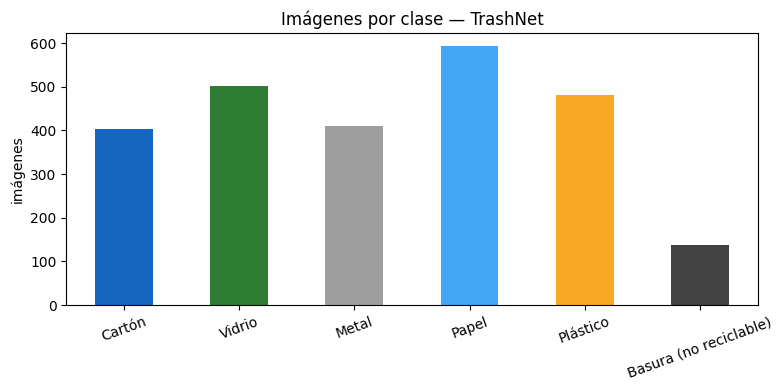

In [4]:
conteo = df["clase"].value_counts().reindex(CLASES_ES)
display(pd.DataFrame({"imágenes": conteo, "% del total": (100 * conteo / conteo.sum()).round(1)}))
print(f"Clase más grande: {conteo.idxmax()} ({conteo.max()}) | más pequeña: {conteo.idxmin()} ({conteo.min()})")
print(f"Razón de desbalance (máx/mín): {conteo.max() / conteo.min():.1f}x")

COLORES = ["#1565c0", "#2e7d32", "#9e9e9e", "#42a5f5", "#f9a825", "#424242"]
ax = conteo.plot(kind="bar", color=COLORES, figsize=(8, 4))
ax.set_title("Imágenes por clase — TrashNet"); ax.set_ylabel("imágenes"); ax.set_xlabel("")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Lectura:** *Basura* tiene muchas menos imágenes que el resto. Por eso:
1. usamos una división **estratificada**, para que cada subconjunto mantenga las proporciones;
2. usamos **pesos por clase** en la función de pérdida;
3. usamos **balanced accuracy** (el promedio del recall de cada clase) como métrica principal, junto con la accuracy.

### 1.2 Ejemplos de cada clase

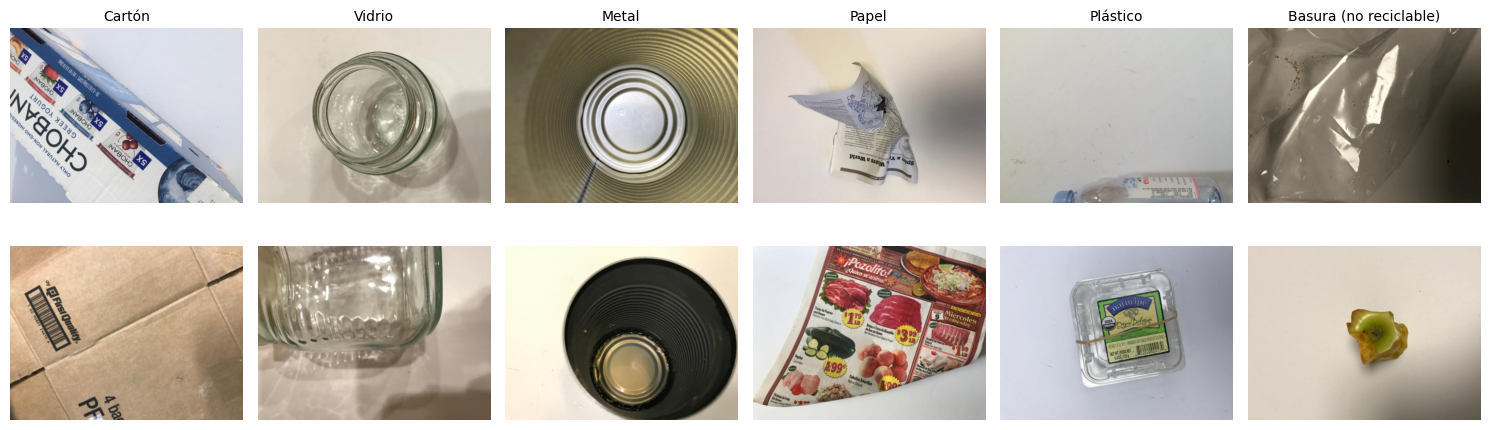

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, nombre in enumerate(CLASES_ES):
    for i, ruta in enumerate(df[df["clase"] == nombre].sample(2, random_state=SEED)["ruta"]):
        axes[i, j].imshow(Image.open(ruta)); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(nombre, fontsize=10)
plt.tight_layout(); plt.show()

### 1.3 Limitaciones de los datos
- **Una sola fuente y fondo controlado:** todas las fotos tienen fondo blanco y un solo objeto. Con fondos reales, varios objetos, suciedad o poca luz, el desempeño probablemente será **menor** que el medido aquí (lo comprobamos en la sección 11 con fotos propias).
- **Pocas imágenes en *Basura***, la clase menos representada.
- **Origen:** envases de Estados Unidos (2016); los envases chilenos pueden verse distintos.
- **Clases cerradas:** el modelo solo conoce 6 clases. Un objeto distinto (pila, tetrapak, cáscara, ropa) igual será asignado a una de ellas.
- **Una etiqueta por foto:** no representa envases mixtos (por ejemplo, cartón con plástico).

## 2. División entrenamiento / validación / prueba

| Conjunto | % | Para qué se usa |
|---|---|---|
| Entrenamiento | 70 % | El modelo aprende con estas imágenes |
| Validación | 15 % | Elegir la mejor época, **elegir el enfoque** (CLIP o EfficientNet) y **elegir el umbral de confianza** |
| Prueba | 15 % | Se usa **una sola vez, al final**, para reportar las métricas definitivas |

La división es estratificada y usa la semilla 42, así que siempre produce los mismos conjuntos.

In [6]:
df_train, df_temp = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
df_val, df_test   = train_test_split(df_temp, test_size=0.50, stratify=df_temp["etiqueta"], random_state=SEED)

tabla_split = pd.DataFrame({"train": df_train["clase"].value_counts(), "val": df_val["clase"].value_counts(),
                            "test": df_test["clase"].value_counts()}).reindex(CLASES_ES)
tabla_split.loc["TOTAL"] = tabla_split.sum()
display(tabla_split)
assert not (set(df_train.ruta) & set(df_val.ruta) or set(df_train.ruta) & set(df_test.ruta) or set(df_val.ruta) & set(df_test.ruta))
print("✅ Sin imágenes repetidas entre conjuntos.")
y_val, y_test = df_val["etiqueta"].to_numpy(), df_test["etiqueta"].to_numpy()

,train,val,test
clase,,,
Cartón,282,61,60
Vidrio,350,75,76
Metal,287,61,62
Papel,416,89,89
Plástico,337,72,73
Basura (no reciclable),96,21,20
TOTAL,1768,379,380


✅ Sin imágenes repetidas entre conjuntos.


## 3. Preprocesamiento (idéntico en el notebook y en la app)

- **Validación, prueba y app:** la función `preprocesar_np` corrige la rotación de las fotos de celular, redimensiona a 224×224 y normaliza. **Es la misma función que `nucleo.preprocesar` en la app**, así que el modelo ve exactamente lo mismo en ambos lugares.
- **Entrenamiento:** además aplica **aumento de datos** (volteos, rotaciones leves y cambios de brillo y contraste) para que el modelo generalice mejor.

In [7]:
MEDIA = np.array([0.485, 0.456, 0.406], dtype=np.float32)   # normalización de ImageNet
DESV  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def abrir_imagen(ruta):
    return ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")

def preprocesar_np(img):
    "MISMO código que nucleo.preprocesar (app). Devuelve (3, 224, 224) float32."
    img = ImageOps.exif_transpose(img).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    x = (np.asarray(img, dtype=np.float32) / 255.0 - MEDIA) / DESV
    return x.transpose(2, 0, 1).astype(np.float32)

tf_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15, fill=255),                       # relleno blanco, como el fondo de las fotos
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.ToTensor(), transforms.Normalize(MEDIA.tolist(), DESV.tolist()),
])

class ResiduosDataset(Dataset):
    def __init__(self, tabla, entrenamiento=False):
        self.rutas, self.etiquetas, self.entrenamiento = tabla["ruta"].tolist(), tabla["etiqueta"].tolist(), entrenamiento
    def __len__(self): return len(self.rutas)
    def __getitem__(self, i):
        img = abrir_imagen(self.rutas[i])
        x = tf_train(img) if self.entrenamiento else torch.from_numpy(preprocesar_np(img))
        return x, self.etiquetas[i]

NUM_WORKERS = 2
dl_train = DataLoader(ResiduosDataset(df_train, True), batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
dl_val   = DataLoader(ResiduosDataset(df_val),         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
dl_test  = DataLoader(ResiduosDataset(df_test),        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# Verificación: el preprocesamiento de la app coincide con el estándar de torchvision
tf_ref = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
                             transforms.Normalize(MEDIA.tolist(), DESV.tolist())])
dif = max(float(np.abs(preprocesar_np(abrir_imagen(r)) - tf_ref(abrir_imagen(r)).numpy()).max()) for r in df_val["ruta"][:10])
print(f"Diferencia máxima preprocesar_np vs torchvision: {dif:.2e}  (≈0 → mismo preprocesamiento)")

Diferencia máxima preprocesar_np vs torchvision: 0.00e+00  (≈0 → mismo preprocesamiento)


## 4. Línea base: CLIP zero-shot (sin entrenar)

**CLIP** (OpenAI) relaciona imágenes con textos. Sin entrenarlo con nuestras fotos, le damos varias descripciones de cada clase y elegimos la más parecida a cada imagen. Responde a la pregunta: **¿hace falta entrenar un modelo propio?**

> 🔧 **Compatibilidad con Transformers 5:** `get_image_features` y `get_text_features` ya no devuelven un tensor, sino un objeto cuyo campo **`pooler_output`** contiene los embeddings proyectados. La función `embeddings()` funciona con ambas versiones.

Aquí calculamos sus métricas en **validación** (para la selección). Su resultado en prueba solo se mira en la sección 7.

In [8]:
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_proc  = CLIPProcessor.from_pretrained(CLIP_ID)

def embeddings(salida):
    "Transformers 5 → objeto con .pooler_output ; Transformers 4 → tensor. Devuelve vectores normalizados."
    e = salida if isinstance(salida, torch.Tensor) else salida.pooler_output
    return e / e.norm(dim=-1, keepdim=True)

DESCRIPCIONES = {   # en inglés, el idioma en que se entrenó CLIP; se promedian varias por clase
    "cardboard": ["a photo of a cardboard box", "a photo of a piece of brown cardboard", "a photo of corrugated cardboard packaging"],
    "glass":     ["a photo of a glass bottle", "a photo of a glass jar", "a photo of a glass container"],
    "metal":     ["a photo of a metal can", "a photo of an aluminum soda can", "a photo of a tin can or metal lid"],
    "paper":     ["a photo of a sheet of paper", "a photo of a newspaper", "a photo of crumpled paper or a paper envelope"],
    "plastic":   ["a photo of a plastic bottle", "a photo of a plastic container", "a photo of a plastic bag or plastic packaging"],
    "trash":     ["a photo of non-recyclable trash", "a photo of a dirty food wrapper", "a photo of mixed garbage"],
}
with torch.no_grad():
    emb_texto = []
    for c in CLASES_EN:
        tok = clip_proc(text=DESCRIPCIONES[c], return_tensors="pt", padding=True).to(DEVICE)
        e = embeddings(clip_model.get_text_features(**tok)).mean(dim=0)
        emb_texto.append(e / e.norm())
    emb_texto = torch.stack(emb_texto)                      # (6, 512)

def predecir_clip(rutas, lote=32):
    probs = []
    with torch.no_grad():
        for i in range(0, len(rutas), lote):
            pix = clip_proc(images=[abrir_imagen(r) for r in rutas[i:i + lote]], return_tensors="pt").to(DEVICE)
            e = embeddings(clip_model.get_image_features(**pix))
            probs.append((100.0 * e @ emb_texto.T).softmax(dim=-1).cpu())
    return torch.cat(probs).numpy()

t0 = time.time()
probs_clip_val  = predecir_clip(df_val["ruta"].tolist())
probs_clip_test = predecir_clip(df_test["ruta"].tolist())   # se guarda; se analiza recién en la sección 7
acc_clip_val, bacc_clip_val = accuracy_score(y_val, probs_clip_val.argmax(1)), balanced_accuracy_score(y_val, probs_clip_val.argmax(1))
print(f"CLIP zero-shot (VALIDACIÓN) → accuracy {acc_clip_val:.3f} | balanced accuracy {bacc_clip_val:.3f}   ({time.time()-t0:.0f}s)")
del clip_model; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot (VALIDACIÓN) → accuracy 0.805 | balanced accuracy 0.808   (9s)


## 5. EfficientNet-B0 con transfer learning

- **EfficientNet-B0** (librería `timm`) viene **preentrenada en ImageNet**, así que ya sabe detectar bordes, texturas y formas.
- Se reemplaza su capa final por una de **6 salidas** y se **ajusta toda la red** con una tasa de aprendizaje baja (*fine-tuning*).
- La **pérdida usa pesos por clase**, para compensar el desbalance.
- En cada época se mide la **balanced accuracy en validación** y se guarda la mejor versión.

In [9]:
modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES_ES)).to(DEVICE)
print(f"Parámetros: {sum(p.numel() for p in modelo.parameters())/1e6:.1f} M")

frec  = np.bincount(df_train["etiqueta"], minlength=len(CLASES_ES))
pesos = torch.tensor(len(df_train) / (len(CLASES_ES) * frec), dtype=torch.float32).to(DEVICE)
print("Pesos por clase:", {c: round(float(w), 2) for c, w in zip(CLASES_ES, pesos.cpu())})

criterio    = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-4)
scheduler   = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCHS)
usar_amp    = DEVICE.type == "cuda"
scaler      = torch.amp.GradScaler("cuda", enabled=usar_amp)

def evaluar(modelo, dl):
    modelo.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in dl:
            with torch.autocast(device_type=DEVICE.type, enabled=usar_amp):
                logits = modelo(x.to(DEVICE))
            P.append(logits.float().softmax(1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Parámetros: 4.0 M
Pesos por clase: {'Cartón': 1.04, 'Vidrio': 0.84, 'Metal': 1.03, 'Papel': 0.71, 'Plástico': 0.87, 'Basura (no reciclable)': 3.07}


In [10]:
historial, mejor_bacc, mejor_epoca = [], -1.0, -1
RUTA_MEJOR = DATA_DIR / "mejor_modelo.pt"

for epoca in range(1, EPOCHS + 1):
    modelo.train(); t0 = time.time(); perdida_total, aciertos, n = 0.0, 0, 0
    for x, y in dl_train:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=usar_amp):
            logits = modelo(x); perdida = criterio(logits, y)
        scaler.scale(perdida).backward(); scaler.step(optimizador); scaler.update()
        perdida_total += perdida.item() * len(y); aciertos += (logits.argmax(1) == y).sum().item(); n += len(y)
    scheduler.step()
    p_v, _ = evaluar(modelo, dl_val)
    acc_v, bacc_v = accuracy_score(y_val, p_v.argmax(1)), balanced_accuracy_score(y_val, p_v.argmax(1))
    historial.append({"época": epoca, "pérdida_train": perdida_total / n, "acc_train": aciertos / n, "acc_val": acc_v, "bacc_val": bacc_v})
    marca = ""
    if bacc_v > mejor_bacc:
        mejor_bacc, mejor_epoca = bacc_v, epoca; torch.save(modelo.state_dict(), RUTA_MEJOR); marca = "  ⭐ mejor"
    print(f"Época {epoca:2d}/{EPOCHS} | pérdida {perdida_total/n:.3f} | acc train {aciertos/n:.3f} | "
          f"acc val {acc_v:.3f} | bacc val {bacc_v:.3f} | {time.time()-t0:.0f}s{marca}")
print(f"\nMejor época: {mejor_epoca} (balanced accuracy en validación = {mejor_bacc:.3f})")

Época  1/12 | pérdida 2.067 | acc train 0.546 | acc val 0.644 | bacc val 0.656 | 36s  ⭐ mejor
Época  2/12 | pérdida 1.085 | acc train 0.787 | acc val 0.757 | bacc val 0.735 | 23s  ⭐ mejor
Época  3/12 | pérdida 0.863 | acc train 0.871 | acc val 0.773 | bacc val 0.750 | 20s  ⭐ mejor
Época  4/12 | pérdida 0.772 | acc train 0.915 | acc val 0.802 | bacc val 0.791 | 13s  ⭐ mejor
Época  5/12 | pérdida 0.711 | acc train 0.934 | acc val 0.810 | bacc val 0.807 | 13s  ⭐ mejor
Época  6/12 | pérdida 0.670 | acc train 0.960 | acc val 0.836 | bacc val 0.828 | 13s  ⭐ mejor
Época  7/12 | pérdida 0.661 | acc train 0.953 | acc val 0.860 | bacc val 0.843 | 13s  ⭐ mejor
Época  8/12 | pérdida 0.637 | acc train 0.971 | acc val 0.858 | bacc val 0.841 | 13s
Época  9/12 | pérdida 0.622 | acc train 0.980 | acc val 0.865 | bacc val 0.850 | 13s  ⭐ mejor
Época 10/12 | pérdida 0.616 | acc train 0.985 | acc val 0.847 | bacc val 0.831 | 13s
Época 11/12 | pérdida 0.613 | acc train 0.980 | acc val 0.865 | bacc val 0.849

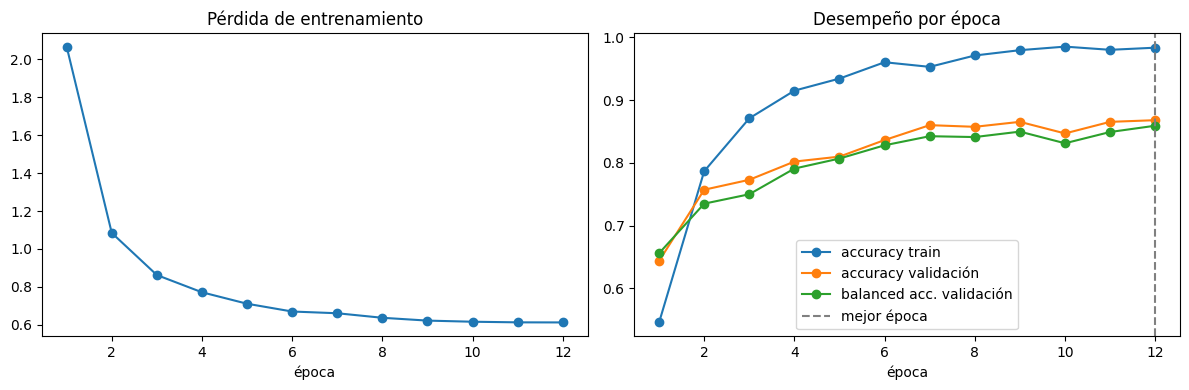

In [11]:
h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["época"], h["pérdida_train"], marker="o"); ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("época")
for col, et in [("acc_train", "accuracy train"), ("acc_val", "accuracy validación"), ("bacc_val", "balanced acc. validación")]:
    ax[1].plot(h["época"], h[col], marker="o", label=et)
ax[1].axvline(mejor_epoca, ls="--", c="gray", label="mejor época"); ax[1].legend(); ax[1].set_xlabel("época"); ax[1].set_title("Desempeño por época")
plt.tight_layout(); plt.show()

**Cómo leerlo:** si la accuracy de entrenamiento sigue subiendo mientras la de validación se estanca, hay **sobreajuste**. Por eso nos quedamos con la mejor época en validación y no con la última.

## 6. Selección del enfoque con VALIDACIÓN

El conjunto de prueba sigue reservado. Comparamos ambos enfoques **en validación, con las mismas métricas** y elegimos según la **balanced accuracy**.

In [12]:
modelo.load_state_dict(torch.load(RUTA_MEJOR, map_location=DEVICE))
probs_eff_val, _ = evaluar(modelo, dl_val)
acc_eff_val, bacc_eff_val = accuracy_score(y_val, probs_eff_val.argmax(1)), balanced_accuracy_score(y_val, probs_eff_val.argmax(1))

tabla_val = pd.DataFrame({"Accuracy": [acc_clip_val, acc_eff_val], "Balanced accuracy": [bacc_clip_val, bacc_eff_val]},
                         index=["CLIP zero-shot", "EfficientNet-B0"])
display(tabla_val.style.format("{:.3f}").highlight_max(color="#c8e6c9").set_caption("VALIDACIÓN"))

GANADOR_VAL = "EfficientNet-B0" if bacc_eff_val >= bacc_clip_val else "CLIP zero-shot"
dif_pp = abs(bacc_eff_val - bacc_clip_val) * 100
if GANADOR_VAL == "EfficientNet-B0":
    MOTIVO = (f"EfficientNet-B0 obtuvo mayor balanced accuracy en validación (+{dif_pp:.1f} puntos porcentuales sobre CLIP), "
              "por eso se usa en la app.")
else:
    MOTIVO = (f"CLIP obtuvo mayor balanced accuracy en validación (+{dif_pp:.1f} p.p.). Aun así, la app usa EfficientNet-B0 "
              "porque CLIP pesa ~600 MB (no cabe en GitHub, que admite máx. 100 MB por archivo) y supera la memoria "
              "del hosting gratuito. Esta diferencia se informa de forma transparente.")
    print("⚠️ ATENCIÓN: CLIP ganó en validación. Revisen este resultado antes de seguir y comenten la decisión en la exposición.")
print("Ganador en validación:", GANADOR_VAL); print("Decisión:", MOTIVO)

,Accuracy,Balanced accuracy
CLIP zero-shot,0.805,0.808
EfficientNet-B0,0.868,0.859


Ganador en validación: EfficientNet-B0
Decisión: EfficientNet-B0 obtuvo mayor balanced accuracy en validación (+5.1 puntos porcentuales sobre CLIP), por eso se usa en la app.


## 7. Evaluación final en PRUEBA (una sola vez)

Ahora sí usamos el conjunto de prueba: imágenes que **ningún** enfoque usó para entrenar ni para tomar decisiones.

,Accuracy,Balanced accuracy
CLIP zero-shot,0.771,0.731
EfficientNet-B0,0.887,0.888


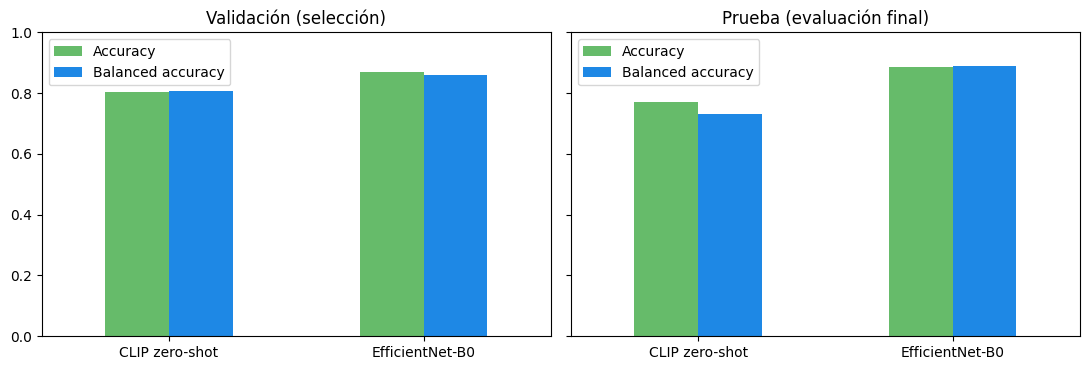

Reporte por clase — EfficientNet-B0 (modelo de la app), PRUEBA:

                        precision    recall  f1-score   support

                Cartón      0.930     0.883     0.906        60
                Vidrio      0.868     0.868     0.868        76
                 Metal      0.855     0.952     0.901        62
                 Papel      0.922     0.933     0.927        89
              Plástico      0.951     0.795     0.866        73
Basura (no reciclable)      0.667     0.900     0.766        20

              accuracy                          0.887       380
             macro avg      0.866     0.888     0.872       380
          weighted avg      0.894     0.887     0.888       380

Reporte por clase — CLIP zero-shot, PRUEBA:

                        precision    recall  f1-score   support

                Cartón      0.877     0.833     0.855        60
                Vidrio      0.897     0.684     0.776        76
                 Metal      0.761     0.871     0.812 

In [13]:
probs_eff_test, y_chk = evaluar(modelo, dl_test)
assert (y_chk == y_test).all()                       # mismo conjunto de prueba para ambos enfoques
pred_eff, pred_clip = probs_eff_test.argmax(1), probs_clip_test.argmax(1)
acc_eff, bacc_eff   = accuracy_score(y_test, pred_eff),  balanced_accuracy_score(y_test, pred_eff)
acc_clip, bacc_clip = accuracy_score(y_test, pred_clip), balanced_accuracy_score(y_test, pred_clip)

tabla_test = pd.DataFrame({"Accuracy": [acc_clip, acc_eff], "Balanced accuracy": [bacc_clip, bacc_eff]},
                          index=["CLIP zero-shot", "EfficientNet-B0"])
display(tabla_test.style.format("{:.3f}").set_caption("PRUEBA"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
tabla_val.plot(kind="bar", ax=ax[0], rot=0, color=["#66bb6a", "#1e88e5"], ylim=(0, 1), title="Validación (selección)")
tabla_test.plot(kind="bar", ax=ax[1], rot=0, color=["#66bb6a", "#1e88e5"], ylim=(0, 1), title="Prueba (evaluación final)")
plt.tight_layout(); plt.show()

print("Reporte por clase — EfficientNet-B0 (modelo de la app), PRUEBA:\n")
print(classification_report(y_test, pred_eff, target_names=CLASES_ES, digits=3, zero_division=0))
reporte_eff = classification_report(y_test, pred_eff, target_names=CLASES_ES, output_dict=True, zero_division=0)
print("Reporte por clase — CLIP zero-shot, PRUEBA:\n")
print(classification_report(y_test, pred_clip, target_names=CLASES_ES, digits=3, zero_division=0))

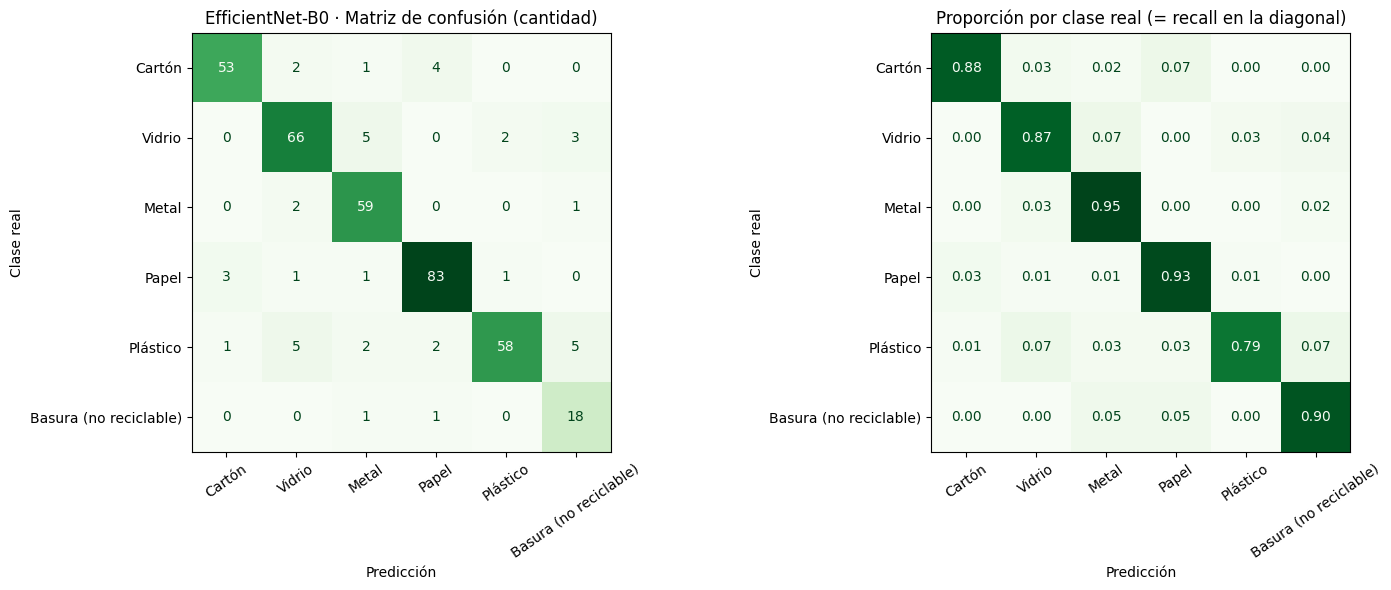

In [14]:
cm = confusion_matrix(y_test, pred_eff, labels=range(len(CLASES_ES)))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASES_ES).plot(ax=ax[0], cmap="Greens", colorbar=False, xticks_rotation=35)
ax[0].set_title("EfficientNet-B0 · Matriz de confusión (cantidad)")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASES_ES).plot(
    ax=ax[1], cmap="Greens", colorbar=False, xticks_rotation=35, values_format=".2f")
ax[1].set_title("Proporción por clase real (= recall en la diagonal)")
for a in ax: a.set_xlabel("Predicción"); a.set_ylabel("Clase real")
plt.tight_layout(); fig.savefig(DATA_DIR / "matriz_confusion.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Errores más costosos

En reciclaje, no todos los errores cuestan lo mismo:

| Error | Consecuencia | Costo |
|---|---|---|
| **Basura → reciclable** | Contamina el contenedor; puede inutilizar un lote completo | 🔴 Alto |
| **Vidrio → papel, cartón o plástico** | Riesgo de cortes y daño a la maquinaria; contamina la fibra o el plástico | 🔴 Alto |
| Reciclable → basura | Se pierde un material recuperable, pero no contamina | 🟡 Medio |
| Papel ↔ cartón | Ambos van al contenedor azul | 🟢 Bajo |

In [15]:
I = {c: i for i, c in enumerate(CLASES_ES)}
iB, iV = I["Basura (no reciclable)"], I["Vidrio"]
n_basura, n_vidrio = int(cm[iB].sum()), int(cm[iV].sum())
basura_como_reciclable = int(n_basura - cm[iB, iB])
vidrio_a_fibra_o_plastico = int(cm[iV, [I["Papel"], I["Cartón"], I["Plástico"]]].sum())
otras = [i for i in range(len(CLASES_ES)) if i != iB]
reciclable_como_basura, n_reciclables = int(cm[otras, iB].sum()), int(cm[otras].sum())

print(f"🔴 Basura predicha como reciclable: {basura_como_reciclable} de {n_basura} ({100*basura_como_reciclable/n_basura:.1f} %)")
print(f"🔴 Vidrio predicho como papel/cartón/plástico: {vidrio_a_fibra_o_plastico} de {n_vidrio} ({100*vidrio_a_fibra_o_plastico/n_vidrio:.1f} %)")
print(f"🟡 Reciclable predicho como basura: {reciclable_como_basura} de {n_reciclables} ({100*reciclable_como_basura/n_reciclables:.1f} %)")
sin_diag = cm.copy(); np.fill_diagonal(sin_diag, 0)
r, c = np.unravel_index(sin_diag.argmax(), cm.shape)
print(f"\nConfusión más frecuente: '{CLASES_ES[r]}' predicho como '{CLASES_ES[c]}' ({sin_diag[r, c]} veces)")

🔴 Basura predicha como reciclable: 2 de 20 (10.0 %)
🔴 Vidrio predicho como papel/cartón/plástico: 2 de 76 (2.6 %)
🟡 Reciclable predicho como basura: 9 de 360 (2.5 %)

Confusión más frecuente: 'Vidrio' predicho como 'Metal' (5 veces)


Errores totales en prueba: 43 de 380


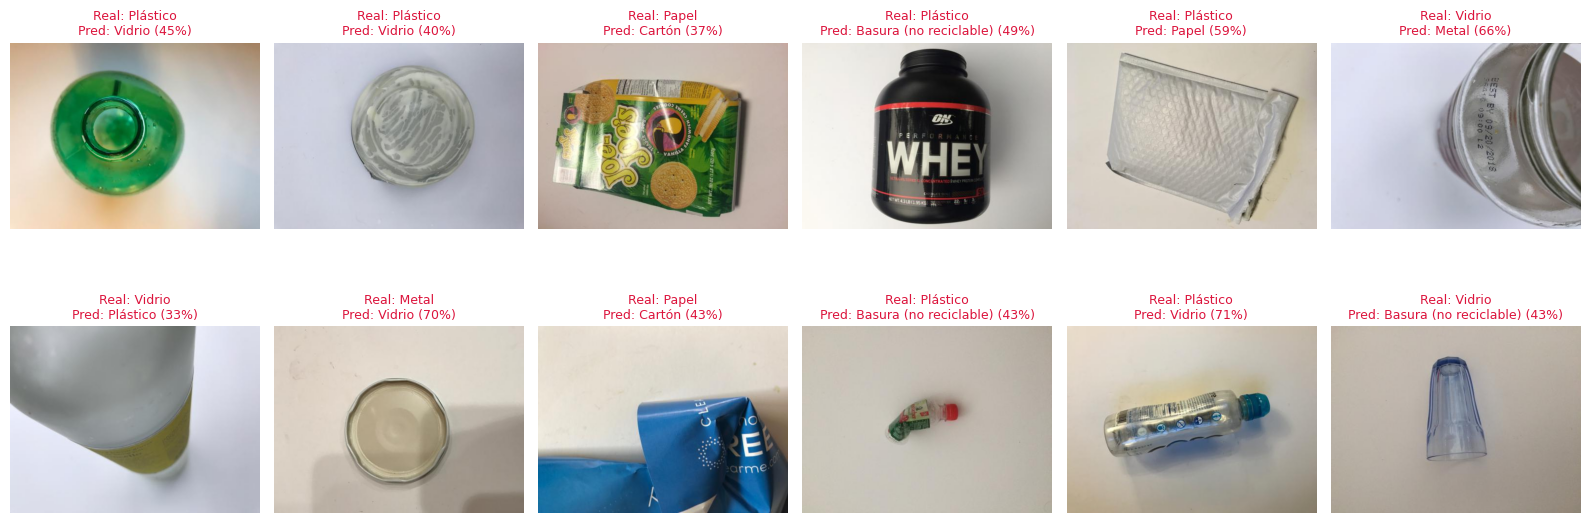

In [16]:
errores = np.where(pred_eff != y_test)[0]
print(f"Errores totales en prueba: {len(errores)} de {len(y_test)}")
if len(errores):
    mostrar = errores[:12]; cols = 6; filas = int(np.ceil(len(mostrar) / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(16, 3.2 * filas)); axes = np.atleast_2d(axes)
    for a in axes.flat: a.axis("off")
    for a, k in zip(axes.flat, mostrar):
        a.imshow(abrir_imagen(df_test["ruta"].iloc[k]))
        a.set_title(f"Real: {CLASES_ES[y_test[k]]}\nPred: {CLASES_ES[pred_eff[k]]} ({probs_eff_test[k].max():.0%})", fontsize=9, color="crimson")
    plt.tight_layout(); plt.show()

## 9. Umbral de confianza para revisión humana (elegido en VALIDACIÓN)

- La **confianza** es la probabilidad que el modelo asigna a su respuesta para **una** imagen.
- La **accuracy** es el porcentaje de aciertos sobre **todo** un conjunto.

**Regla:** elegimos el umbral **más bajo** con el que, en **validación**, las predicciones aceptadas (confianza ≥ umbral) aciertan al menos un `OBJETIVO_PRECISION_UMBRAL` (95 %). Bajo ese umbral, la app pide revisión humana. Después solo **comprobamos** el umbral en prueba, sin volver a ajustarlo.

> Nota: el entrenamiento usa *label smoothing*, por eso las confianzas rara vez llegan a 100 %. La regla se adapta a eso automáticamente.

,umbral,cobertura,accuracy_aceptadas
0,0.30,99.2%,87.0%
1,0.35,98.4%,87.4%
2,0.40,95.0%,89.2%
3,0.45,91.6%,90.8%
4,0.50,88.1%,91.3%
5,0.55,83.4%,93.4%
6,0.60,76.0%,95.5%
7,0.65,71.5%,96.7%
8,0.70,64.4%,98.0%
9,0.75,60.2%,98.7%


UMBRAL ELEGIDO = 0.60  (menor umbral cuyas predicciones aceptadas logran ≥95% de accuracy en validación)
  Validación: cobertura 76.0%, accuracy de las aceptadas 95.5%
  Prueba: cobertura 78.9%, accuracy sobre el umbral 96.0%, bajo el umbral 61.3% (80 imágenes)


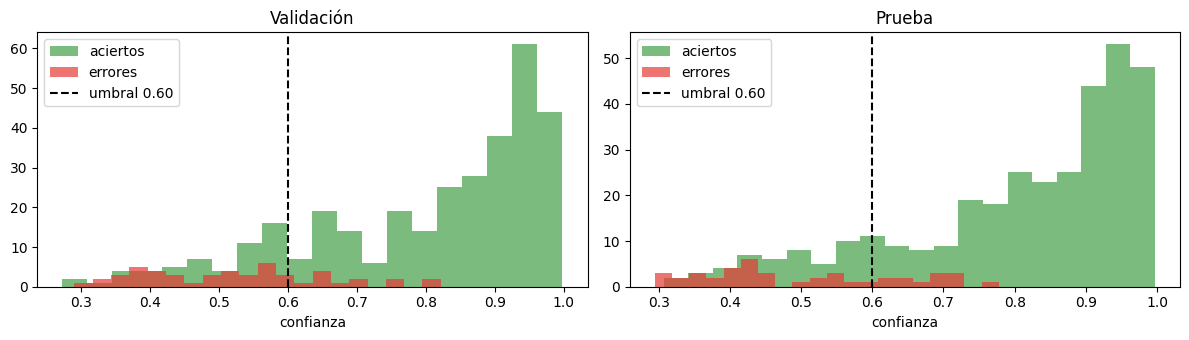

In [17]:
conf_val, ok_val = probs_eff_val.max(1), probs_eff_val.argmax(1) == y_val
grilla = np.round(np.arange(0.30, 0.96, 0.05), 2)
filas_u = []
for t in grilla:
    m = conf_val >= t
    filas_u.append({"umbral": t, "cobertura": m.mean(), "accuracy_aceptadas": ok_val[m].mean() if m.any() else np.nan})
tabla_umbral = pd.DataFrame(filas_u)
display(tabla_umbral.style.format({"umbral": "{:.2f}", "cobertura": "{:.1%}", "accuracy_aceptadas": "{:.1%}"}).set_caption("VALIDACIÓN"))

cumple = tabla_umbral[(tabla_umbral.accuracy_aceptadas >= OBJETIVO_PRECISION_UMBRAL) & (tabla_umbral.cobertura > 0)]
if len(cumple):
    UMBRAL = float(cumple.umbral.min())
    CRITERIO_UMBRAL = (f"menor umbral cuyas predicciones aceptadas logran ≥{OBJETIVO_PRECISION_UMBRAL:.0%} de accuracy en validación")
else:   # si el objetivo no se alcanza, se usa el umbral con mejor accuracy que mantenga al menos 50 % de cobertura
    candidatos = tabla_umbral[tabla_umbral.cobertura >= 0.5]
    UMBRAL = float(candidatos.loc[candidatos.accuracy_aceptadas.idxmax(), "umbral"]) if len(candidatos) else float(grilla.min())
    CRITERIO_UMBRAL = (f"no se alcanzó {OBJETIVO_PRECISION_UMBRAL:.0%}; umbral con mayor accuracy manteniendo ≥50 % de cobertura en validación")
fila = tabla_umbral[tabla_umbral.umbral == UMBRAL].iloc[0]
print(f"UMBRAL ELEGIDO = {UMBRAL:.2f}  ({CRITERIO_UMBRAL})")
print(f"  Validación: cobertura {fila.cobertura:.1%}, accuracy de las aceptadas {fila.accuracy_aceptadas:.1%}")

# Comprobación en PRUEBA (sin reajustar)
conf_test, ok_test = probs_eff_test.max(1), pred_eff == y_test
alta = conf_test >= UMBRAL
acc_alta = float(ok_test[alta].mean()) if alta.any() else float("nan")
acc_baja = float(ok_test[~alta].mean()) if (~alta).any() else None
print(f"  Prueba: cobertura {alta.mean():.1%}, accuracy sobre el umbral {acc_alta:.1%}, "
      f"bajo el umbral {'sin imágenes' if acc_baja is None else f'{acc_baja:.1%}'} ({(~alta).sum()} imágenes)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, conf, ok, t in [(ax[0], conf_val, ok_val, "Validación"), (ax[1], conf_test, ok_test, "Prueba")]:
    a.hist(conf[ok], bins=20, alpha=.7, label="aciertos", color="#43a047"); a.hist(conf[~ok], bins=20, alpha=.7, label="errores", color="#e53935")
    a.axvline(UMBRAL, ls="--", c="k", label=f"umbral {UMBRAL:.2f}"); a.set_title(t); a.set_xlabel("confianza"); a.legend()
plt.tight_layout(); plt.show()

## 10. Exportar el modelo y verificar la app

Archivos que se generan (**solo existen después de ejecutar este notebook**):
```
modelo/modelo_residuos.onnx   ← el modelo que usa la app (onnxruntime, sin PyTorch)
modelo/modelo_residuos.pt     ← pesos de PyTorch (respaldo / evidencia)
modelo/clases.json            ← clases y preprocesamiento
modelo/metricas.json          ← métricas REALES (la app las lee)
modelo/matriz_confusion.png   ← para la app, el README y la presentación
ejemplos/*.jpg                ← una imagen de PRUEBA por clase
```

In [18]:
SALIDA = Path("/content/entrega") if Path("/content").exists() else Path("entrega")
if SALIDA.exists(): shutil.rmtree(SALIDA)
(SALIDA / "modelo").mkdir(parents=True); (SALIDA / "ejemplos").mkdir()

modelo_cpu = modelo.float().cpu().eval()
torch.save(modelo_cpu.state_dict(), SALIDA / "modelo/modelo_residuos.pt")

# Exportación a ONNX (un solo archivo con los pesos incluidos)
ruta_onnx = SALIDA / "modelo/modelo_residuos.onnx"
x_ej = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
try:
    torch.onnx.export(modelo_cpu, x_ej, ruta_onnx, input_names=["imagen"], output_names=["logits"],
                      dynamic_axes={"imagen": {0: "lote"}, "logits": {0: "lote"}}, opset_version=18, dynamo=False)
    metodo = "torchscript"
except Exception as e:
    print("Exportador clásico no disponible, uso el nuevo:", type(e).__name__)
    torch.onnx.export(modelo_cpu, (x_ej,), ruta_onnx, input_names=["imagen"], output_names=["logits"],
                      dynamic_shapes=({0: torch.export.Dim("lote")},), opset_version=18, dynamo=True, external_data=False)
    metodo = "dynamo"
tam_mb = ruta_onnx.stat().st_size / 1e6
print(f"ONNX exportado ({metodo}): {tam_mb:.1f} MB")
assert tam_mb > 5, "El .onnx quedó sin pesos: revisar la exportación"
assert not list((SALIDA / "modelo").glob("*.data")), "No debe haber archivos .data separados"

ONNX exportado (torchscript): 16.0 MB


In [19]:
# VERIFICACIÓN: la app (onnxruntime + preprocesar_np) predice igual que PyTorch en TODO el conjunto de prueba
sesion = ort.InferenceSession(str(ruta_onnx), providers=["CPUExecutionProvider"])
def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

probs_app = []
for i in range(0, len(df_test), 64):
    lote = np.stack([preprocesar_np(Image.open(r)) for r in df_test["ruta"].iloc[i:i + 64]])
    probs_app.append(softmax(sesion.run(None, {"imagen": lote})[0]))
probs_app = np.concatenate(probs_app)

coinciden = int((probs_app.argmax(1) == pred_eff).sum())
dif_max = float(np.abs(probs_app - probs_eff_test).max())
print(f"Predicciones idénticas app vs notebook: {coinciden}/{len(df_test)}")
print(f"Diferencia máxima de probabilidad: {dif_max:.2e}  (pequeña por la precisión mixta de la GPU)")
print(f"Accuracy de la app en prueba: {accuracy_score(y_test, probs_app.argmax(1)):.3f} (notebook: {acc_eff:.3f})")

Predicciones idénticas app vs notebook: 379/380
Diferencia máxima de probabilidad: 1.97e-02  (pequeña por la precisión mixta de la GPU)
Accuracy de la app en prueba: 0.884 (notebook: 0.887)


In [20]:
shutil.copy(DATA_DIR / "matriz_confusion.png", SALIDA / "modelo/matriz_confusion.png")
json.dump({"arquitectura": "efficientnet_b0", "formato": "onnx", "clases": CLASES_ES, "carpetas_originales": CLASES_EN,
           "img_size": IMG_SIZE, "media": MEDIA.tolist(), "desv": DESV.tolist()},
          open(SALIDA / "modelo/clases.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

r4 = lambda v: round(float(v), 4)
METRICAS = {
    "fecha": datetime.date.today().isoformat(),
    "dataset": "TrashNet — Gary Thung y Mindy Yang (Stanford CS229, 2016). github.com/garythung/trashnet",
    "licencia_dataset": "MIT",
    "n_imagenes": {"train": len(df_train), "val": len(df_val), "test": len(df_test)},
    "entrenamiento": {"epocas": EPOCHS, "mejor_epoca": mejor_epoca, "lr": LR, "batch": BATCH_SIZE, "seed": SEED},
    "seleccion": {
        "criterio": "mayor balanced accuracy en el conjunto de validación",
        "validacion": {"efficientnet_b0": {"accuracy": r4(acc_eff_val), "balanced_accuracy": r4(bacc_eff_val)},
                       "clip_zero_shot": {"accuracy": r4(acc_clip_val), "balanced_accuracy": r4(bacc_clip_val)}},
        "ganador_validacion": GANADOR_VAL, "modelo_desplegado": "EfficientNet-B0", "motivo": MOTIVO},
    "prueba": {
        "efficientnet_b0": {"accuracy": r4(acc_eff), "balanced_accuracy": r4(bacc_eff)},
        "clip_zero_shot": {"accuracy": r4(acc_clip), "balanced_accuracy": r4(bacc_clip)},
        "modelo_desplegado": {"accuracy": r4(acc_eff), "balanced_accuracy": r4(bacc_eff),
                              "precision_por_clase": {c: r4(reporte_eff[c]["precision"]) for c in CLASES_ES},
                              "recall_por_clase": {c: r4(reporte_eff[c]["recall"]) for c in CLASES_ES}}},
    "errores_costosos": {"basura_como_reciclable": basura_como_reciclable, "n_basura": n_basura,
                         "vidrio_como_fibra_o_plastico": vidrio_a_fibra_o_plastico, "n_vidrio": n_vidrio,
                         "reciclable_como_basura": reciclable_como_basura, "n_reciclables": n_reciclables},
    "umbral_confianza": {"valor": UMBRAL, "criterio": CRITERIO_UMBRAL,
                         "validacion": {"cobertura": r4(fila.cobertura), "accuracy_aceptadas": r4(fila.accuracy_aceptadas)},
                         "prueba": {"cobertura": r4(alta.mean()), "accuracy_aceptadas": r4(acc_alta),
                                    "accuracy_bajo_umbral_txt": "sin imágenes" if acc_baja is None else f"{acc_baja:.1%}".replace(".", ",")}},
    "verificacion_app": {"predicciones_identicas": coinciden, "n": len(df_test), "dif_max_prob": dif_max, "exportador_onnx": metodo},
    "fotos_reales": None,
    "versiones": VERSIONES,
}
json.dump(METRICAS, open(SALIDA / "modelo/metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

for idx, carpeta in enumerate(CLASES_EN):   # una imagen de PRUEBA por clase (nunca vista al entrenar)
    abrir_imagen(df_test[df_test["etiqueta"] == idx]["ruta"].iloc[0]).save(SALIDA / "ejemplos" / f"{carpeta}.jpg", quality=90)

print(json.dumps({k: METRICAS[k] for k in ["seleccion", "prueba", "umbral_confianza"]}, ensure_ascii=False, indent=1))

{
 "seleccion": {
  "criterio": "mayor balanced accuracy en el conjunto de validación",
  "validacion": {
   "efficientnet_b0": {
    "accuracy": 0.8681,
    "balanced_accuracy": 0.8593
   },
   "clip_zero_shot": {
    "accuracy": 0.8047,
    "balanced_accuracy": 0.8079
   }
  },
  "ganador_validacion": "EfficientNet-B0",
  "modelo_desplegado": "EfficientNet-B0",
  "motivo": "EfficientNet-B0 obtuvo mayor balanced accuracy en validación (+5.1 puntos porcentuales sobre CLIP), por eso se usa en la app."
 },
 "prueba": {
  "efficientnet_b0": {
   "accuracy": 0.8868,
   "balanced_accuracy": 0.8884
  },
  "clip_zero_shot": {
   "accuracy": 0.7711,
   "balanced_accuracy": 0.731
  },
  "modelo_desplegado": {
   "accuracy": 0.8868,
   "balanced_accuracy": 0.8884,
   "precision_por_clase": {
    "Cartón": 0.9298,
    "Vidrio": 0.8684,
    "Metal": 0.8551,
    "Papel": 0.9222,
    "Plástico": 0.9508,
    "Basura (no reciclable)": 0.6667
   },
   "recall_por_clase": {
    "Cartón": 0.8833,
    "Vi

In [21]:
def empaquetar_y_descargar():
    zip_path = shutil.make_archive(str(SALIDA.parent / "entrega_modelo"), "zip", SALIDA)
    print("Archivo listo:", zip_path, f"({Path(zip_path).stat().st_size/1e6:.1f} MB)")
    try:
        from google.colab import files; files.download(zip_path)
    except ImportError:
        pass
empaquetar_y_descargar()

Archivo listo: /content/entrega_modelo.zip (30.2 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. *(Opcional, recomendado)* Prueba con fotografías reales del grupo

TrashNet tiene solo fotos con fondo blanco. Para saber cómo funciona la app **en la vida real**, tomen **fotos propias** con el celular (al menos 5 por clase, con fondos y luces normales).

1. Creen una carpeta `fotos_reales` con estas subcarpetas: `carton`, `papel`, `plastico`, `vidrio`, `metal`, `basura`.
2. Pongan cada foto en la subcarpeta de su material, comprímanla como **`fotos_reales.zip`** y arrástrenla al panel de archivos de Colab (📁, a la izquierda, dentro de `/content`).
3. Ejecuten las dos celdas siguientes. El resultado se agrega a `metricas.json` y se vuelve a descargar el zip.

Si el archivo no está, la celda solo muestra estas instrucciones (no produce errores).

In [22]:
MAPA_REALES = {"carton": "Cartón", "papel": "Papel", "plastico": "Plástico", "vidrio": "Vidrio", "metal": "Metal", "basura": "Basura (no reciclable)"}
zip_reales = Path("/content/fotos_reales.zip") if Path("/content").exists() else Path("fotos_reales.zip")
resultados_reales = None
if not zip_reales.exists():
    print("ℹ️ No se encontró fotos_reales.zip → se omite esta prueba (ver instrucciones arriba).")
else:
    destino = DATA_DIR / "fotos_reales"; shutil.rmtree(destino, ignore_errors=True)
    with zipfile.ZipFile(zip_reales) as z: z.extractall(destino)
    filas_r = []
    for carpeta, clase in MAPA_REALES.items():
        for f in sorted(p for p in destino.rglob("*") if p.parent.name.lower() == carpeta and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}):
            pr = softmax(sesion.run(None, {"imagen": preprocesar_np(Image.open(f))[None]})[0])[0]
            filas_r.append({"archivo": f.name, "real": clase, "predicción": CLASES_ES[pr.argmax()], "confianza": pr.max()})
    resultados_reales = pd.DataFrame(filas_r)
    if resultados_reales.empty:
        print("⚠️ El zip no tiene fotos en las subcarpetas esperadas:", list(MAPA_REALES))
    else:
        resultados_reales["acierto"] = resultados_reales["real"] == resultados_reales["predicción"]
        display(resultados_reales.style.format({"confianza": "{:.0%}"}))
        print(f"Fotos reales: {len(resultados_reales)} | accuracy {resultados_reales.acierto.mean():.1%} | "
              f"bajo el umbral: {(resultados_reales.confianza < UMBRAL).mean():.1%}")

ℹ️ No se encontró fotos_reales.zip → se omite esta prueba (ver instrucciones arriba).


In [23]:
if resultados_reales is not None and not resultados_reales.empty:
    METRICAS["fotos_reales"] = {"n": int(len(resultados_reales)), "accuracy": r4(resultados_reales.acierto.mean()),
                                "fraccion_bajo_umbral": r4((resultados_reales.confianza < UMBRAL).mean()),
                                "por_clase": resultados_reales.groupby("real").acierto.agg(["sum", "count"]).astype(int).to_dict("index")}
    json.dump(METRICAS, open(SALIDA / "modelo/metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    empaquetar_y_descargar()
else:
    print("Sin fotos reales: metricas.json queda con fotos_reales = null.")

Sin fotos reales: metricas.json queda con fotos_reales = null.


## 12. *(Opcional, recomendado)* Probar la clave de Gemini antes de publicar

1. Crea la clave gratis en **aistudio.google.com/apikey**.
2. En Colab, abre el panel 🔑 **Secretos** (a la izquierda) → *Agregar nuevo secreto* → nombre `GEMINI_API_KEY`, valor: tu clave → activa **Acceso al notebook**.
3. Ejecuta la celda. La clave **no se imprime**.

In [24]:
from google import genai
try:
    from google.colab import userdata
    CLAVE = userdata.get("GEMINI_API_KEY")
except Exception:
    CLAVE = os.environ.get("GEMINI_API_KEY")

if not CLAVE:
    print("ℹ️ No hay secreto GEMINI_API_KEY → se omite la prueba (ver instrucciones arriba).")
else:
    cliente = genai.Client(api_key=CLAVE)
    for m in ["gemini-3.5-flash-lite", "gemini-3.6-flash", "gemini-flash-lite-latest", "gemini-flash-latest"]:
        try:
            r = cliente.models.generate_content(model=m, contents="Responde solo: OK. ¿En qué contenedor va una botella de vidrio en Chile? (máx. 10 palabras)")
            print(f"✅ {m} funciona → respuesta: {r.text.strip()[:80]}")
            print(f"   La app usará este modelo por defecto. (Si quieres fijarlo, crea el secreto GEMINI_MODEL = {m})")
            break
        except Exception as e:
            print(f"❌ {m}: {type(e).__name__} {str(e)[:120]}")

ℹ️ No hay secreto GEMINI_API_KEY → se omite la prueba (ver instrucciones arriba).


## ✅ Al terminar
1. Descomprime **`entrega_modelo.zip`** y copia `modelo/` y `ejemplos/` en la carpeta del proyecto.
2. Guarda **este notebook ejecutado**: `Archivo → Descargar → Descargar .ipynb` → reemplaza `notebooks/entrenamiento.ipynb`. La pauta exige que se vean los resultados.
3. Envía el contenido de `modelo/metricas.json` para revisarlo antes de publicar.